In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn as sk

In [2]:
df = pd.read_csv('credit_risk_dataset.csv')

In [5]:
df

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4
...,...,...,...,...,...,...,...,...,...,...,...,...
32576,57,53000,MORTGAGE,1.0,PERSONAL,C,5800,13.16,0,0.11,N,30
32577,54,120000,MORTGAGE,4.0,PERSONAL,A,17625,7.49,0,0.15,N,19
32578,65,76000,RENT,3.0,HOMEIMPROVEMENT,B,35000,10.99,1,0.46,N,28
32579,56,150000,MORTGAGE,5.0,PERSONAL,B,15000,11.48,0,0.10,N,26


In [4]:
df.shape

(32581, 12)

In [7]:
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


In [9]:
data_rows = df.shape[0]
data_colunms = df.shape[1]

print(f'This dataset have {data_rows} rows and {data_colunms} columns.')

This dataset have 32581 rows and 12 columns.


In [10]:
df.isnull().sum()

person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64

In [11]:
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


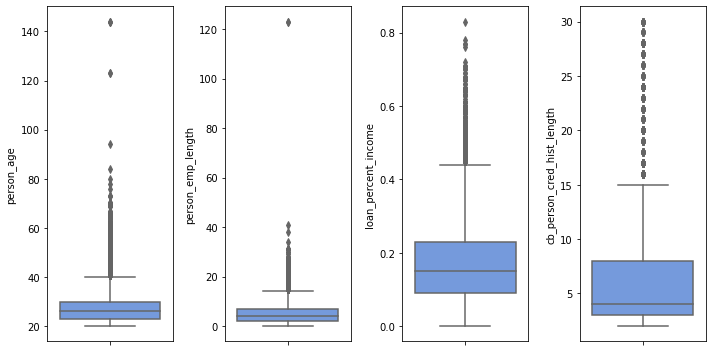

In [12]:
features = ['person_age','person_emp_length','loan_percent_income','cb_person_cred_hist_length']
plt.figure(figsize=(10,5))
for i in range(0,len(features)):
    plt.subplot(1, len(features), i + 1)
    sns.boxplot(y=df[features[i]], color='CornflowerBlue', orient='v')
    plt.tight_layout()

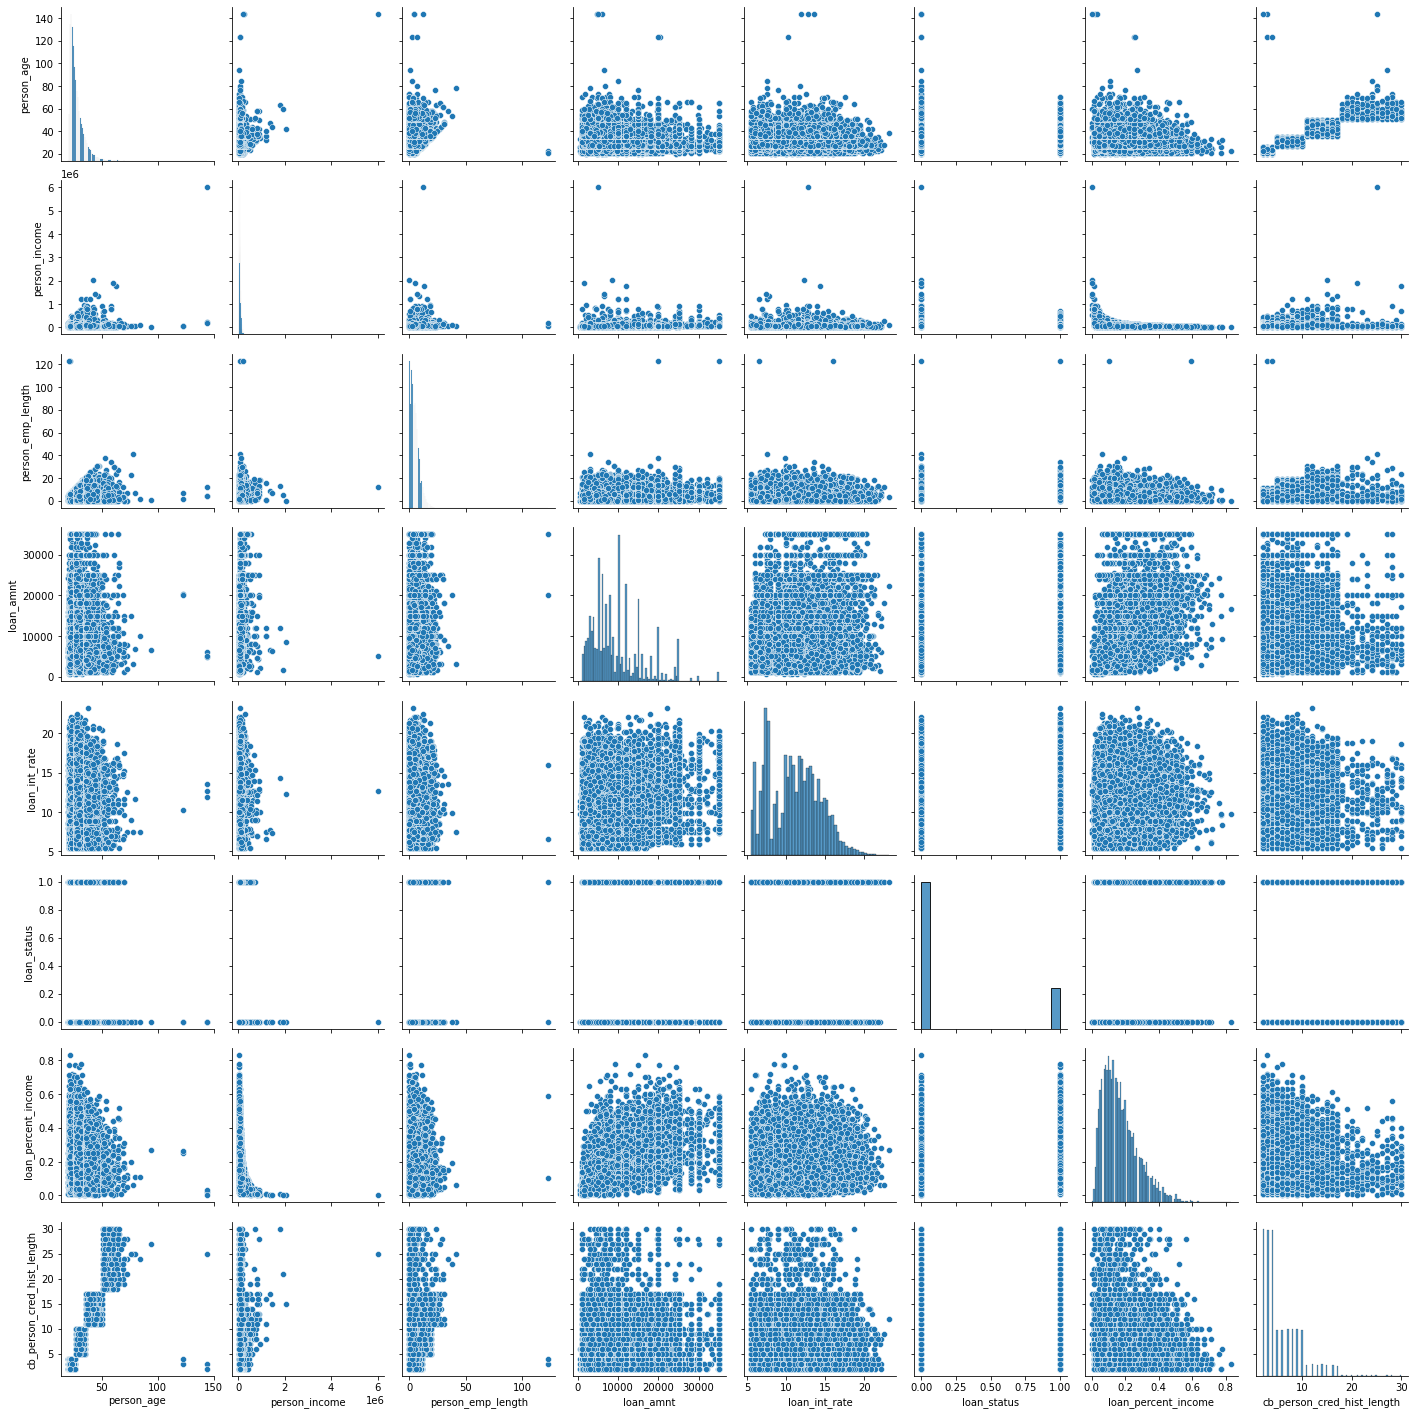

In [13]:
sns.pairplot(df)

In [14]:
df.loan_status.value_counts()

0    25473
1     7108
Name: loan_status, dtype: int64

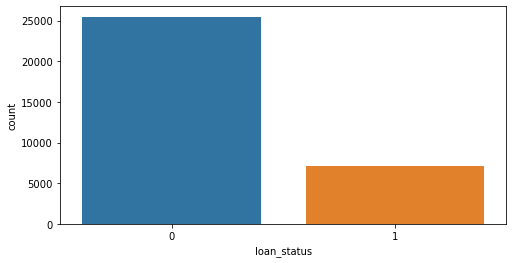

In [15]:
plt.figure(figsize=(8,4))
sns.countplot(x='loan_status', data=df)
plt.show()

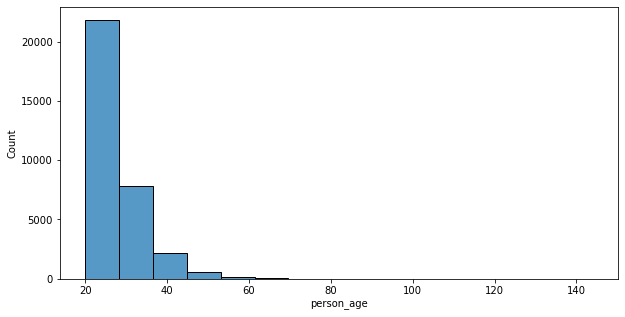

In [16]:
plt.figure(figsize=(10,5))
sns.histplot(data=df, x= 'person_age', bins=15)
plt.show()

In [4]:
variables = ['person_age','person_income','person_emp_length', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length', 'loan_status']
credit_risk_corr = df[variables].corr()
credit_risk_corr

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,loan_status
person_age,1.000000,0.173202,0.163106,0.050787,0.012580,-0.042411,0.859133,-0.021629
person_income,0.173202,1.000000,0.134268,0.266820,0.000792,-0.254471,0.117987,-0.144449
person_emp_length,0.163106,0.134268,1.000000,0.113082,-0.056405,-0.054111,0.144699,-0.082489
loan_amnt,0.050787,0.266820,0.113082,1.000000,0.146813,0.572612,0.041967,0.105376
loan_int_rate,0.012580,0.000792,-0.056405,0.146813,1.000000,0.120314,0.016696,0.335133
loan_percent_income,-0.042411,-0.254471,-0.054111,0.572612,0.120314,1.000000,-0.031690,0.379366
cb_person_cred_hist_length,0.859133,0.117987,0.144699,0.041967,0.016696,-0.031690,1.000000,-0.015529
loan_status,-0.021629,-0.144449,-0.082489,0.105376,0.335133,0.379366,-0.015529,1.000000


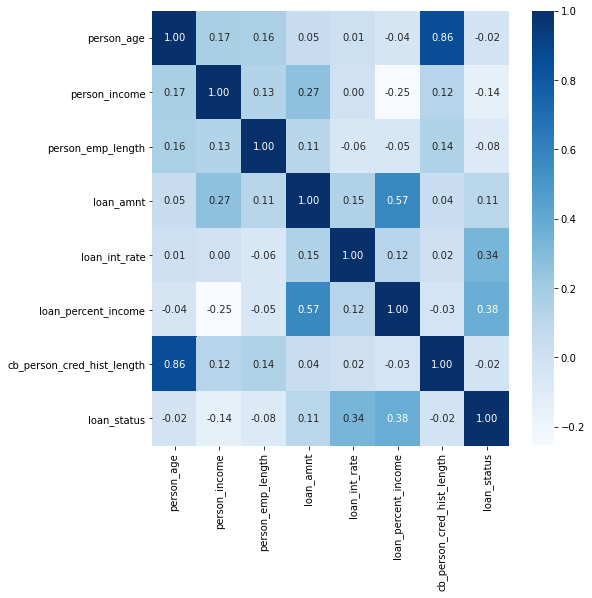

In [5]:
plt.figure(figsize=(8,8))
sns.heatmap(credit_risk_corr, cmap='Blues', annot=True, fmt='.2f')
plt.show()

In [6]:
cat_cols = ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']
for i in cat_cols:
    print(f'Total row of variable {i}')
    print(df[i].value_counts())
    print()
   

Total row of variable person_home_ownership
RENT        16446
MORTGAGE    13444
OWN          2584
OTHER         107
Name: person_home_ownership, dtype: int64

Total row of variable loan_intent
EDUCATION            6453
MEDICAL              6071
VENTURE              5719
PERSONAL             5521
DEBTCONSOLIDATION    5212
HOMEIMPROVEMENT      3605
Name: loan_intent, dtype: int64

Total row of variable loan_grade
A    10777
B    10451
C     6458
D     3626
E      964
F      241
G       64
Name: loan_grade, dtype: int64

Total row of variable cb_person_default_on_file
N    26836
Y     5745
Name: cb_person_default_on_file, dtype: int64



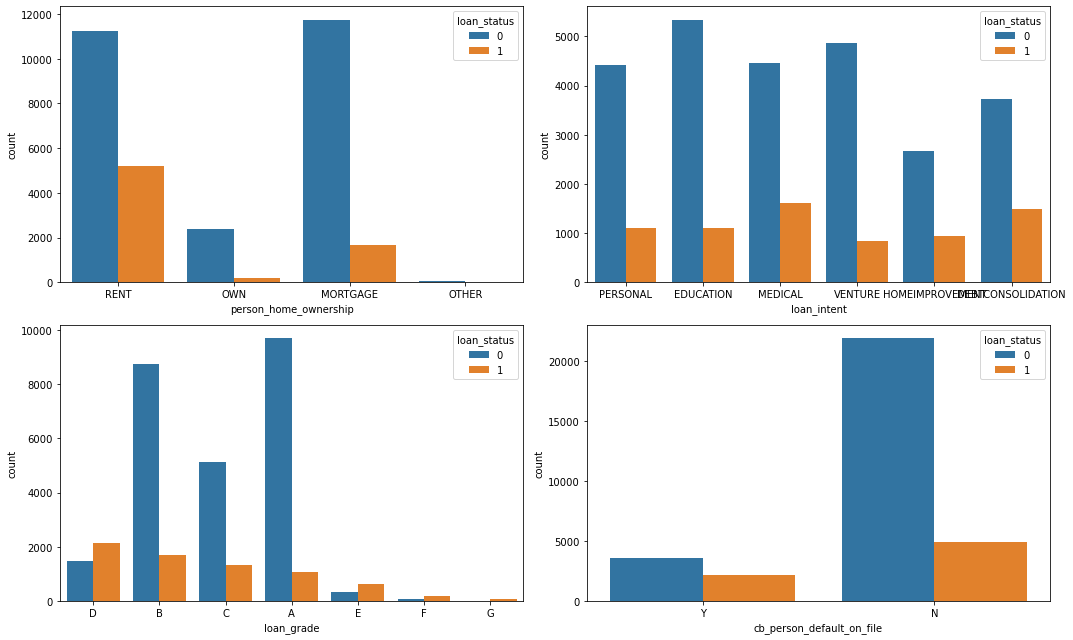

In [6]:
plt.figure(figsize=(15,9))
for i in range(0,len(cat_cols)):
    plt.subplot(2,2,i + 1)
    sns.countplot(data= df, x = cat_cols[i], hue='loan_status')
    plt.tight_layout()

In [7]:
df.drop(df.loc[df['person_emp_length'] == 123].index, inplace=True)

In [8]:
df.drop(df.loc[df['person_age'] >= 123].index, inplace=True)

In [9]:
df.loc[df['person_age'] >= 123].index

Int64Index([], dtype='int64')

In [10]:
num_cols = pd.DataFrame(df[df.select_dtypes(include=['float', 'int']).columns])

/opt/anaconda3/lib/python3.8/site-packages/seaborn/distributions.py:2551: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)
/opt/anaconda3/lib/python3.8/site-packages/seaborn/distributions.py:2551: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)
/opt/anaconda3/lib/python3.8/site-packages/seaborn/distributions.py:2551: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-lev

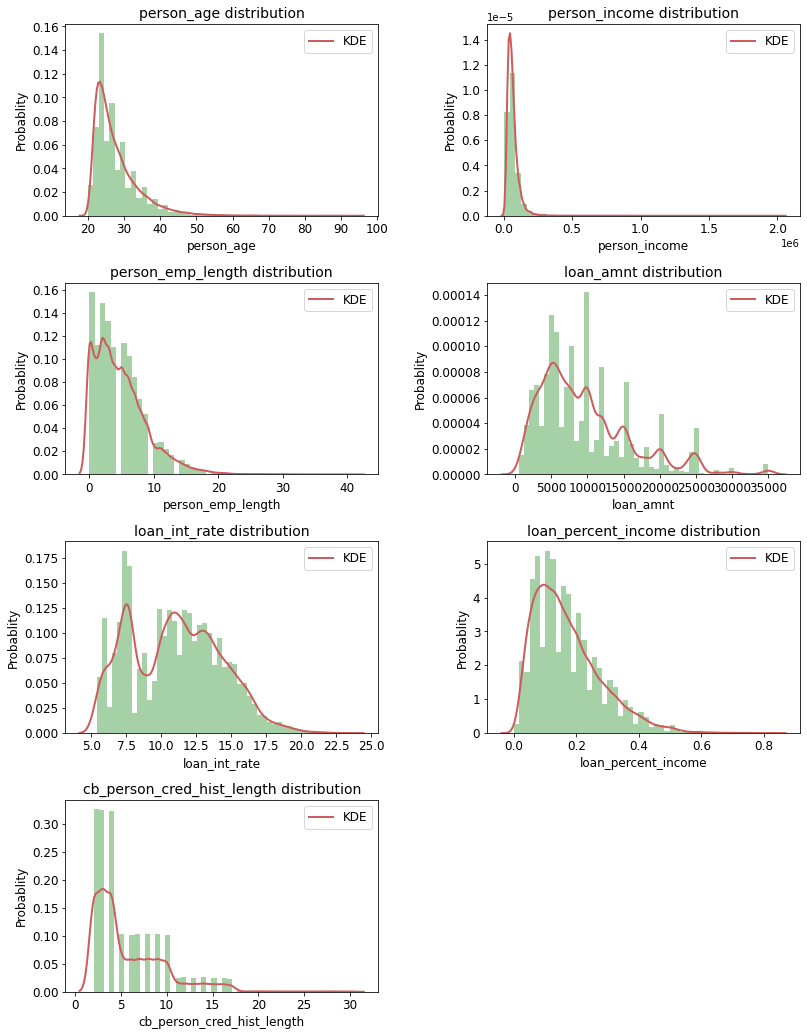

In [15]:
num_cols_hist = num_cols.drop(['loan_status'], axis=1)
plt.figure(figsize=(12,16))

for i, col in enumerate(num_cols_hist.columns):
    idx = int('42'+ str(i+1))
    plt.subplot(idx)
    sns.distplot(num_cols_hist[col], color='forestgreen', 
                 kde_kws={'color': 'indianred', 'lw': 2, 'label': 'KDE'})
    plt.title(col+' distribution', fontsize=14)
    plt.ylabel('Probablity', fontsize=12)
    plt.xlabel(col, fontsize=12)
    plt.xticks(fontsize=12)
    plt.yticks(fontsize=12)
    plt.legend(['KDE'], prop={"size":12})

plt.subplots_adjust(top=0.92, bottom=0.08, left=0.10, right=0.95, hspace=0.35,
                    wspace=0.35)
plt.show()

In [11]:
df = df[df['person_age']<=100]
df = df[df['person_emp_length']<=60]
df = df[df['person_income']<=4e6]

In [12]:
mean_person_emp_length = df['person_emp_length'].mean()
mean_loan_int_rate = df['loan_int_rate'].mean()

df['person_emp_length'] = df['person_emp_length'].fillna(mean_person_emp_length) 
df['loan_int_rate'] = df['loan_int_rate'].fillna(mean_loan_int_rate) 

In [13]:
from sklearn.preprocessing import LabelEncoder

In [14]:
label_encoder = LabelEncoder()
df["loan_intent"]=label_encoder.fit_transform(df["loan_intent"])
df["person_home_ownership"]=label_encoder.fit_transform(df["person_home_ownership"])
df["loan_grade"]=label_encoder.fit_transform(df["loan_grade"])
df["cb_person_default_on_file"]=label_encoder.fit_transform(df["cb_person_default_on_file"])

In [15]:
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
1,21,9600,2,5.0,1,1,1000,11.14,0,0.10,0,2
2,25,9600,0,1.0,3,2,5500,12.87,1,0.57,0,3
3,23,65500,3,4.0,3,2,35000,15.23,1,0.53,0,2
4,24,54400,3,8.0,3,2,35000,14.27,1,0.55,1,4
5,21,9900,2,2.0,5,0,2500,7.14,1,0.25,0,2


In [16]:
df["person_age"].max()

94

In [17]:
df.isnull().sum()

person_age                    0
person_income                 0
person_home_ownership         0
person_emp_length             0
loan_intent                   0
loan_grade                    0
loan_amnt                     0
loan_int_rate                 0
loan_status                   0
loan_percent_income           0
cb_person_default_on_file     0
cb_person_cred_hist_length    0
dtype: int64

In [18]:
from scipy.stats import uniform, randint
from sklearn import model_selection,linear_model, metrics
from sklearn.metrics import auc, accuracy_score, confusion_matrix, roc_auc_score, classification_report
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier
from sklearn.metrics import plot_confusion_matrix

In [19]:
R_tree=RandomForestClassifier()
lg = LogisticRegression(random_state=42)
N_bayes=GaussianNB()
knn = KNeighborsClassifier(n_neighbors=150)
XGB_model = XGBClassifier(learning_rate=0.1, max_depth=10, scale_pos_weight=1.5, eval_metric='mlogloss')

In [20]:
label = df['loan_status'] # labels
features = df.drop('loan_status',axis=1) # features
x_train, x_test, y_train, y_test = model_selection.train_test_split(features, label,stratify=label,
                                                                    random_state=42, test_size=.30)
print('The train dataset has {} data\nThe test dataset has {} data'.
      format(x_train.shape[0], x_test.shape[0]))

The train dataset has 22175 data
The test dataset has 9504 data


In [24]:
from sklearn.model_selection import cross_val_score
scores = cross_val_score(R_tree, x_train, y_train, cv = 10, scoring='accuracy') 
print('Cross-validation scores:{}'.format(scores))

Cross-validation scores:[0.9220018  0.93688007 0.93462579 0.93237151 0.93146979 0.9300857
 0.932341   0.93279206 0.93053676 0.92061344]


In [25]:
scores = cross_val_score(knn, x_train, y_train, cv = 10, scoring='accuracy') 
print('Cross-validation scores:{}'.format(scores))

Cross-validation scores:[0.83453562 0.8367899  0.83769161 0.84039675 0.83047791 0.83942264
 0.83400992 0.8488949  0.83897158 0.8285972 ]


In [24]:
scores = cross_val_score(N_bayes, x_train, y_train, cv = 10, scoring='accuracy') 
print('Cross-validation scores:{}'.format(scores))

Cross-validation scores:[0.81514878 0.81875564 0.82506763 0.81650135 0.82100992 0.82318448
 0.82995038 0.81145692 0.81686964 0.81867388]


In [26]:
scores = cross_val_score(lg, x_train, y_train, cv = 10, scoring='accuracy') 
print('Cross-validation scores:{}'.format(scores))

Cross-validation scores:[0.80342651 0.8097385  0.80297565 0.81244364 0.80613165 0.81235904
 0.81326116 0.8105548  0.8015336  0.80514208]


In [29]:
scores = cross_val_score(XGB_model, x_train, y_train, cv = 10, scoring='accuracy') 
print('Cross-validation scores:{}'.format(scores))

/opt/anaconda3/lib/python3.8/site-packages/xgboost/sklearn.py:1224: UserWarning: The use of label encoder in XGBClassifier is deprecated and will be removed in a future release. To remove this warning, do the following: 1) Pass option use_label_encoder=False when constructing XGBClassifier object; and 2) Encode your labels (y) as integers starting with 0, i.e. 0, 1, 2, ..., [num_class - 1].
  warnings.warn(label_encoder_deprecation_msg, UserWarning)


Cross-validation scores:[0.93327322 0.9418395  0.93958521 0.9355275  0.94274121 0.9391069
 0.93594948 0.94091114 0.92918358 0.92737934]


In [21]:
def model_assess(model, name='Default'):
    model.fit(x_train, y_train)
    preds = model.predict(x_test)
    preds_proba = model.predict_proba(x_test)
    print(name, '\n',classification_report(y_test, model.predict(x_test)))
    print(confusion_matrix(y_test,preds))
   

In [22]:
N_bayes=GaussianNB()
model_assess(N_bayes, name='Naive bayes')

lg = LogisticRegression(random_state=42)
model_assess(lg, 'Logistic Regression')

R_tree=RandomForestClassifier()
model_assess(R_tree,'RandomForest Classifier')

XGB_model = XGBClassifier(learning_rate=0.1, max_depth=10, scale_pos_weight=1.5, eval_metric='mlogloss')
model_assess(XGB_model,'Xgboost')

knn = KNeighborsClassifier(n_neighbors=150)
model_assess(knn, name='KNN')


Naive bayes 
               precision    recall  f1-score   support

           0       0.85      0.96      0.90      7456
           1       0.70      0.37      0.48      2048

    accuracy                           0.83      9504
   macro avg       0.77      0.66      0.69      9504
weighted avg       0.81      0.83      0.81      9504

[[7135  321]
 [1296  752]]
Logistic Regression 
               precision    recall  f1-score   support

           0       0.81      0.98      0.89      7456
           1       0.71      0.15      0.25      2048

    accuracy                           0.80      9504
   macro avg       0.76      0.57      0.57      9504
weighted avg       0.79      0.80      0.75      9504

[[7327  129]
 [1738  310]]
RandomForest Classifier 
               precision    recall  f1-score   support

           0       0.93      0.99      0.96      7456
           1       0.97      0.71      0.82      2048

    accuracy                           0.93      9504
   macro avg

/opt/anaconda3/lib/python3.8/site-packages/xgboost/sklearn.py:1224: UserWarning: The use of label encoder in XGBClassifier is deprecated and will be removed in a future release. To remove this warning, do the following: 1) Pass option use_label_encoder=False when constructing XGBClassifier object; and 2) Encode your labels (y) as integers starting with 0, i.e. 0, 1, 2, ..., [num_class - 1].
  warnings.warn(label_encoder_deprecation_msg, UserWarning)


Xgboost 
               precision    recall  f1-score   support

           0       0.93      0.99      0.96      7456
           1       0.95      0.75      0.84      2048

    accuracy                           0.94      9504
   macro avg       0.94      0.87      0.90      9504
weighted avg       0.94      0.94      0.93      9504

[[7373   83]
 [ 517 1531]]
KNN 
               precision    recall  f1-score   support

           0       0.85      0.96      0.90      7456
           1       0.71      0.38      0.49      2048

    accuracy                           0.83      9504
   macro avg       0.78      0.67      0.70      9504
weighted avg       0.82      0.83      0.81      9504

[[7144  312]
 [1276  772]]


In [23]:
from tabulate import tabulate

In [25]:
head = ["Model", "Accuracy", "Precision", "Recall", "F1-score"]

final_metrics = [
    ["Naive Bayes", 0.83, 0.81, 0.83, 0.81],
    ["Logistic Regression", 0.80, 0.79, 0.80, 0.75],
    ["KNN Classifier", 0.83, 0.82, 0.83, 0.81],
    ["RandomForestClassifier", 0.93, 0.94, 0.93, 0.93],
    ["Xgboost", 0.94, 0.94, 0.94, 0.93]
]

print(tabulate(final_metrics, headers = head))

Model                     Accuracy    Precision    Recall    F1-score
----------------------  ----------  -----------  --------  ----------
Naive Bayes                   0.83         0.81      0.83        0.81
Logistic Regression           0.8          0.79      0.8         0.75
KNN Classifier                0.83         0.82      0.83        0.81
RandomForestClassifier        0.93         0.94      0.93        0.93
Xgboost                       0.94         0.94      0.94        0.93


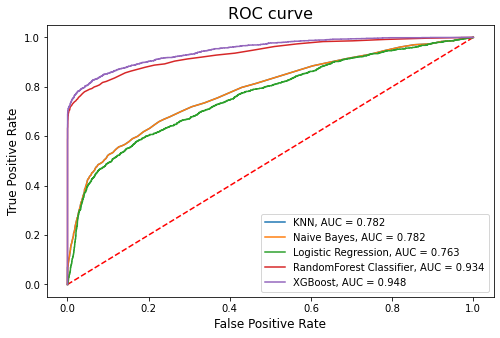

In [24]:
### ROC AUC
fig = plt.figure(figsize=(8,5))
plt.plot([0, 1], [0, 1],'r--')

preds_proba_knn = knn.predict_proba(x_test)
probsknn = preds_proba_knn[:, 1]
fpr, tpr, thresh = metrics.roc_curve(y_test, probsknn)
aucknn = roc_auc_score(y_test, probsknn)
plt.plot(fpr, tpr, label=f'KNN, AUC = {str(round(aucknn,3))}')


preds_proba_N_bayes = N_bayes.predict_proba(x_test)
probsknn = preds_proba_knn[:, 1]
fpr, tpr, thresh = metrics.roc_curve(y_test, probsknn)
aucknn = roc_auc_score(y_test, probsknn)
plt.plot(fpr, tpr, label=f'Naive Bayes, AUC = {str(round(aucknn,3))}')

#Logistic Regression
preds_proba_lg = lg.predict_proba(x_test)
probslg = preds_proba_lg[:, 1]
fpr, tpr, thresh = metrics.roc_curve(y_test, probslg)
auclg = roc_auc_score(y_test, probslg)
plt.plot(fpr, tpr, label=f'Logistic Regression, AUC = {str(round(auclg,3))}')


#RandomForest Classifier
preds_proba_R_tree = R_tree.predict_proba(x_test)
probsR_tree = preds_proba_R_tree[:, 1]
fpr, tpr, thresh = metrics.roc_curve(y_test, probsR_tree)
auclg = roc_auc_score(y_test, probsR_tree)
plt.plot(fpr, tpr, label=f'RandomForest Classifier, AUC = {str(round(auclg,3))}')

#XGBoost
preds_proba_xgb = XGB_model.predict_proba(x_test)
probsxgb = preds_proba_xgb[:, 1]
fpr, tpr, thresh = metrics.roc_curve(y_test, probsxgb)
aucxgb = roc_auc_score(y_test, probsxgb)
plt.plot(fpr, tpr, label=f'XGBoost, AUC = {str(round(aucxgb,3))}')


plt.ylabel("True Positive Rate", fontsize=12)
plt.xlabel("False Positive Rate", fontsize=12)
plt.title("ROC curve")
plt.rcParams['axes.titlesize'] = 16
plt.legend()
plt.show()

In [44]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import plot_confusion_matrix


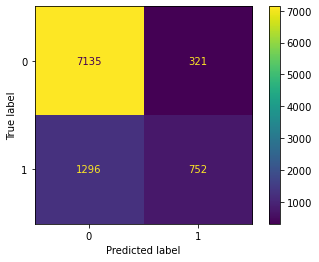

In [55]:
plot_confusion_matrix(N_bayes, x_test, y_test)



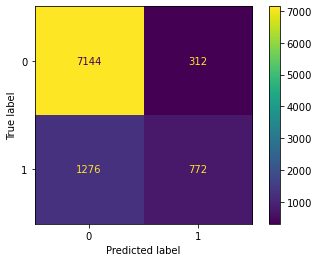

In [47]:
plot_confusion_matrix(knn, x_test, y_test)

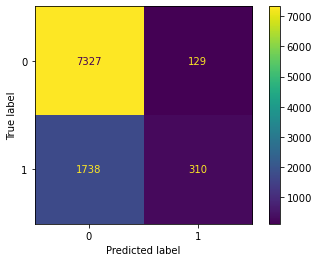

In [53]:
plot_confusion_matrix(lg, x_test, y_test)


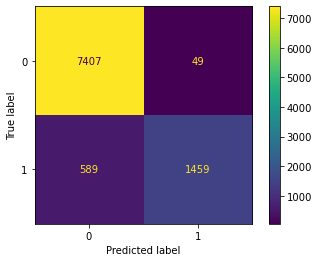

In [54]:
plot_confusion_matrix(R_tree, x_test, y_test)


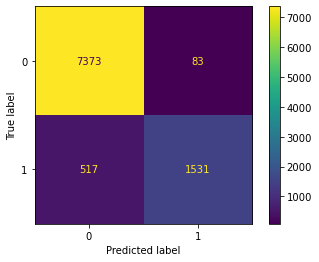

In [52]:
plot_confusion_matrix(XGB_model, x_test, y_test)


In [ ]:
# KNeighbors Classifier

In [20]:
grid_params = { 'n_neighbors' : [5,7,9,11,13,15],
               'weights' : ['uniform','distance'],
               'metric' : ['minkowski','euclidean','manhattan']}

In [22]:
from sklearn.model_selection import GridSearchCV
gs = GridSearchCV(KNeighborsClassifier(), grid_params, verbose = 1, cv=3, n_jobs = -1)

In [24]:
gs.fit(x_train,y_train)
print(f"Best Score: {gs.best_score_}")
print("Standard Devaition:",gs.cv_results_['std_test_score'][gs.best_index_])
print("Best parameters set:")
best_parameters = gs.best_estimator_.get_params()
for param_name in sorted(grid_params.keys()):
  print(f"\t{param_name}: {best_parameters[param_name]}")

Fitting 3 folds for each of 36 candidates, totalling 108 fits


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=-1)]: Done  34 tasks      | elapsed:    2.5s


Best Score: 0.8443741381478156
Standard Devaition: 0.0026381041572729655
Best parameters set:
	metric: manhattan
	n_neighbors: 15
	weights: distance


[Parallel(n_jobs=-1)]: Done 108 out of 108 | elapsed:    4.1s finished


In [25]:
g_res = gs.fit(x_train, y_train)

Fitting 3 folds for each of 36 candidates, totalling 108 fits


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=-1)]: Done  52 tasks      | elapsed:    1.4s
[Parallel(n_jobs=-1)]: Done  93 out of 108 | elapsed:    2.4s remaining:    0.4s
[Parallel(n_jobs=-1)]: Done 108 out of 108 | elapsed:    2.6s finished


In [26]:
g_res.best_score_

0.8443741381478156

In [27]:
g_res.best_params_

{'metric': 'manhattan', 'n_neighbors': 15, 'weights': 'distance'}

In [29]:
gs.cv_results_

{'mean_fit_time': array([0.01980527, 0.02273178, 0.01814699, 0.01506909, 0.01476296,
        0.01354043, 0.01763638, 0.0174063 , 0.01560052, 0.01899862,
        0.01533469, 0.01836165, 0.02015591, 0.01979065, 0.01539906,
        0.01603564, 0.01616542, 0.02649546, 0.02269872, 0.02020168,
        0.02297354, 0.01473769, 0.01523765, 0.02088189, 0.01633183,
        0.01526435, 0.01779874, 0.01459511, 0.01727955, 0.01563287,
        0.01556404, 0.01617463, 0.01763264, 0.01729361, 0.01944129,
        0.01521993]),
 'std_fit_time': array([0.00091651, 0.00280681, 0.00531391, 0.00046639, 0.00235131,
        0.00237108, 0.00385144, 0.00349112, 0.00057997, 0.00360965,
        0.00229705, 0.00504082, 0.00418873, 0.00333105, 0.00258746,
        0.00081245, 0.0020103 , 0.01149337, 0.00599883, 0.00429664,
        0.00231726, 0.00463833, 0.00293435, 0.00754423, 0.0037103 ,
        0.00132434, 0.00365387, 0.00206031, 0.00069261, 0.00243998,
        0.00063608, 0.00057184, 0.00382713, 0.00414399, 0.005

In [30]:
result=pd.DataFrame(gs.cv_results_)
print(result)

    mean_fit_time  std_fit_time  mean_score_time  std_score_time param_metric  \
0        0.019805      0.000917         0.240762        0.008229    minkowski   
1        0.022732      0.002807         0.046491        0.005142    minkowski   
2        0.018147      0.005314         0.225082        0.014113    minkowski   
3        0.015069      0.000466         0.053202        0.007352    minkowski   
4        0.014763      0.002351         0.227087        0.028251    minkowski   
5        0.013540      0.002371         0.040757        0.003098    minkowski   
6        0.017636      0.003851         0.241883        0.038533    minkowski   
7        0.017406      0.003491         0.058300        0.002113    minkowski   
8        0.015601      0.000580         0.254720        0.039714    minkowski   
9        0.018999      0.003610         0.067163        0.005365    minkowski   
10       0.015335      0.002297         0.249167        0.011807    minkowski   
11       0.018362      0.005

In [ ]:
# Logistic Regression

In [31]:
LR_param_grid = {
    'C': np.logspace(0, 4, num=10),
    'penalty': ['l2'],
    'solver': ['liblinear','saga','newton-cg','lbfgs']
}

In [32]:
logistic = LogisticRegression()

Logistic_model = model_selection.RandomizedSearchCV(
    estimator = logistic,
    param_distributions = LR_param_grid,
    n_iter = 20,
    scoring = "accuracy",
    verbose = 5,
    n_jobs = 1,
    cv = 5
)

In [33]:
Logistic_model.fit(x_train,y_train)
print(f"Best Score: {Logistic_model.best_score_}")
print("Standard Devaition:",Logistic_model.cv_results_['std_test_score'][Logistic_model.best_index_])
print("Best parameters set:")
best_parameters = Logistic_model.best_estimator_.get_params()
for param_name in sorted(LR_param_grid.keys()):
print(f"\t{param_name}: {best_parameters[param_name]}")

Fitting 5 folds for each of 20 candidates, totalling 100 fits
[CV] solver=newton-cg, penalty=l2, C=21.544346900318832 ..............


[Parallel(n_jobs=1)]: Using backend SequentialBackend with 1 concurrent workers.
/opt/anaconda3/lib/python3.8/site-packages/scipy/optimize/linesearch.py:477: LineSearchWarning: The line search algorithm did not converge
  warn('The line search algorithm did not converge', LineSearchWarning)
/opt/anaconda3/lib/python3.8/site-packages/scipy/optimize/linesearch.py:327: LineSearchWarning: The line search algorithm did not converge
  warn('The line search algorithm did not converge', LineSearchWarning)
/opt/anaconda3/lib/python3.8/site-packages/sklearn/utils/optimize.py:211: ConvergenceWarning: newton-cg failed to converge. Increase the number of iterations.
  warnings.warn("newton-cg failed to converge. Increase the "
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.6s remaining:    0.0s


[CV]  solver=newton-cg, penalty=l2, C=21.544346900318832, score=0.841, total=   0.6s
[CV] solver=newton-cg, penalty=l2, C=21.544346900318832 ..............


/opt/anaconda3/lib/python3.8/site-packages/scipy/optimize/linesearch.py:477: LineSearchWarning: The line search algorithm did not converge
  warn('The line search algorithm did not converge', LineSearchWarning)
/opt/anaconda3/lib/python3.8/site-packages/scipy/optimize/linesearch.py:327: LineSearchWarning: The line search algorithm did not converge
  warn('The line search algorithm did not converge', LineSearchWarning)
/opt/anaconda3/lib/python3.8/site-packages/scipy/optimize/linesearch.py:477: LineSearchWarning: The line search algorithm did not converge
  warn('The line search algorithm did not converge', LineSearchWarning)
/opt/anaconda3/lib/python3.8/site-packages/scipy/optimize/linesearch.py:327: LineSearchWarning: The line search algorithm did not converge
  warn('The line search algorithm did not converge', LineSearchWarning)
/opt/anaconda3/lib/python3.8/site-packages/scipy/optimize/linesearch.py:477: LineSearchWarning: The line search algorithm did not converge
  warn('The line 

[CV]  solver=newton-cg, penalty=l2, C=21.544346900318832, score=0.848, total=   0.6s
[CV] solver=newton-cg, penalty=l2, C=21.544346900318832 ..............


...

/opt/anaconda3/lib/python3.8/site-packages/sklearn/linear_model/_sag.py:329: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn("The max_iter was reached which means "


[CV]  solver=saga, penalty=l2, C=2.7825594022071245, score=0.811, total=   0.2s
[CV] solver=saga, penalty=l2, C=2.7825594022071245 ...................


/opt/anaconda3/lib/python3.8/site-packages/sklearn/linear_model/_sag.py:329: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn("The max_iter was reached which means "
[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:   23.4s finished


[CV]  solver=saga, penalty=l2, C=2.7825594022071245, score=0.802, total=   0.2s
Best Score: 0.8457271702367531
Standard Devaition: 0.005124680124769941
Best parameters set:
	C: 59.94842503189409
	penalty: l2
	solver: newton-cg


/opt/anaconda3/lib/python3.8/site-packages/scipy/optimize/linesearch.py:477: LineSearchWarning: The line search algorithm did not converge
  warn('The line search algorithm did not converge', LineSearchWarning)
/opt/anaconda3/lib/python3.8/site-packages/scipy/optimize/linesearch.py:327: LineSearchWarning: The line search algorithm did not converge
  warn('The line search algorithm did not converge', LineSearchWarning)
/opt/anaconda3/lib/python3.8/site-packages/scipy/optimize/linesearch.py:477: LineSearchWarning: The line search algorithm did not converge
  warn('The line search algorithm did not converge', LineSearchWarning)
/opt/anaconda3/lib/python3.8/site-packages/scipy/optimize/linesearch.py:327: LineSearchWarning: The line search algorithm did not converge
  warn('The line search algorithm did not converge', LineSearchWarning)
/opt/anaconda3/lib/python3.8/site-packages/scipy/optimize/linesearch.py:477: LineSearchWarning: The line search algorithm did not converge
  warn('The line 

In [34]:
Logistic_model.cv_results_

{'mean_fit_time': array([0.60576491, 0.01789865, 0.20223923, 0.20076528, 0.64459615,
        0.01796274, 0.63561707, 0.20858283, 0.20496206, 0.04289246,
        0.04218559, 0.60432382, 0.65315065, 0.04150758, 0.01874418,
        0.04258528, 0.01881323, 0.02018046, 0.20426989, 0.20889564]),
 'std_fit_time': array([0.04925154, 0.00227371, 0.0021942 , 0.0020789 , 0.01315948,
        0.00142151, 0.03296847, 0.00603425, 0.00143005, 0.00682262,
        0.00641753, 0.00899923, 0.0311405 , 0.00569562, 0.00133522,
        0.00694027, 0.00182796, 0.00201667, 0.00283887, 0.00290232]),
 'mean_score_time': array([0.00159802, 0.00116835, 0.00187278, 0.00176234, 0.00157585,
        0.00117164, 0.00139194, 0.00192318, 0.00171061, 0.00137129,
        0.00137019, 0.00149293, 0.00152178, 0.00137038, 0.00121737,
        0.00137825, 0.00117159, 0.00139918, 0.00151815, 0.00189476]),
 'std_score_time': array([1.09841134e-04, 2.02622691e-05, 2.51576546e-04, 2.29276446e-04,
        2.49128802e-04, 9.44209096e-

In [35]:
result=pd.DataFrame(Logistic_model.cv_results_)
print(result)

    mean_fit_time  std_fit_time  mean_score_time  std_score_time param_solver  \
0        0.605765      0.049252         0.001598        0.000110    newton-cg   
1        0.017899      0.002274         0.001168        0.000020        lbfgs   
2        0.202239      0.002194         0.001873        0.000252         saga   
3        0.200765      0.002079         0.001762        0.000229         saga   
4        0.644596      0.013159         0.001576        0.000249    newton-cg   
5        0.017963      0.001422         0.001172        0.000094        lbfgs   
6        0.635617      0.032968         0.001392        0.000070    newton-cg   
7        0.208583      0.006034         0.001923        0.000287         saga   
8        0.204962      0.001430         0.001711        0.000251         saga   
9        0.042892      0.006823         0.001371        0.000081    liblinear   
10       0.042186      0.006418         0.001370        0.000089    liblinear   
11       0.604324      0.008

In [ ]:
# Naive Bayes

In [33]:
from sklearn.model_selection import RandomizedSearchCV
classifier2 = RandomizedSearchCV(R_tree,params,cv=5)

In [31]:
params = {
'var_smoothing': np.logspace(0,-9, num=100)
}

In [34]:
classifier4 = RandomizedSearchCV(N_bayes,params,cv=5)

In [35]:
classifier4.fit(x_train,y_train)

RandomizedSearchCV(cv=5, estimator=GaussianNB(),
                   param_distributions={'var_smoothing': array([1.00000000e+00, 8.11130831e-01, 6.57933225e-01, 5.33669923e-01,
       4.32876128e-01, 3.51119173e-01, 2.84803587e-01, 2.31012970e-01,
       1.87381742e-01, 1.51991108e-01, 1.23284674e-01, 1.00000000e-01,
       8.11130831e-02, 6.57933225e-02, 5.33669923e-02, 4.32876128e-02,
       3.51119173e-02, 2.84...
       1.23284674e-07, 1.00000000e-07, 8.11130831e-08, 6.57933225e-08,
       5.33669923e-08, 4.32876128e-08, 3.51119173e-08, 2.84803587e-08,
       2.31012970e-08, 1.87381742e-08, 1.51991108e-08, 1.23284674e-08,
       1.00000000e-08, 8.11130831e-09, 6.57933225e-09, 5.33669923e-09,
       4.32876128e-09, 3.51119173e-09, 2.84803587e-09, 2.31012970e-09,
       1.87381742e-09, 1.51991108e-09, 1.23284674e-09, 1.00000000e-09])})

In [36]:
classifier4.cv_results_

{'mean_fit_time': array([0.00831461, 0.00435195, 0.00388036, 0.00346899, 0.0034637 ,
        0.00345373, 0.00345793, 0.00346546, 0.00343475, 0.00344124]),
 'std_fit_time': array([3.59709244e-03, 3.73388572e-04, 7.00713065e-04, 1.57052527e-05,
        2.10842920e-05, 1.00487138e-05, 1.91464222e-05, 3.87259299e-05,
        9.38121819e-06, 1.49772418e-05]),
 'mean_score_time': array([0.00240235, 0.00149393, 0.00117865, 0.00113735, 0.00112734,
        0.00112901, 0.00114446, 0.00113096, 0.00111995, 0.00112214]),
 'std_score_time': array([4.61878940e-04, 2.06275147e-04, 7.02234960e-05, 7.44629737e-06,
        5.05222414e-06, 4.86186870e-06, 2.53878958e-05, 1.16553282e-05,
        5.67135611e-06, 4.37704305e-06]),
 'param_var_smoothing': masked_array(data=[5.3366992312063123e-05, 0.12328467394420659,
                    0.002848035868435802, 3.5111917342151273e-09,
                    6.579332246575682e-07, 2.848035868435799e-06,
                    8.111308307896872e-07, 1e-05, 0.0003511191

In [37]:
best_parameters=classifier4.best_params_ 
print(best_parameters)

{'var_smoothing': 3.5111917342151273e-09}


In [38]:
highest_accuracy=classifier4.best_score_ 
print(highest_accuracy)

0.803652762119504
